# 02. 랜덤 포레스트(Random Forest) 기반 고객 이탈 예측 모델링

In [26]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import joblib

from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score
)

# 한글 폰트 설정 (Windows 기준)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 프로젝트 기본 경로
PROJECT_DIR = Path(".").resolve()
DATA_DIR = PROJECT_DIR / "data" / "processed"
MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("데이터 디렉터리:", DATA_DIR)
print("모델 저장 디렉터리:", MODELS_DIR)

데이터 디렉터리: C:\Users\playdata2\Workspace\Projects\music_churn_data_v1\data\processed
모델 저장 디렉터리: C:\Users\playdata2\Workspace\Projects\music_churn_data_v1\models


## 1. 데이터 로드 및 데이터셋 무결성 확인

`data/processed/`에 사전에 7:1.5:1.5 층화 분할(Stratified Split)되어 저장된 train, valid, test 파일을 읽어옵니다.

In [27]:
train_df = pd.read_csv(DATA_DIR / "train_20181101_v1.csv")
valid_df = pd.read_csv(DATA_DIR / "valid_20181101_v1.csv")
test_df = pd.read_csv(DATA_DIR / "test_20181101_v1.csv")

print(f"Train 데이터 크기: {train_df.shape} (이탈률: {train_df['churn'].mean() * 100:.2f}%)")
print(f"Valid 데이터 크기: {valid_df.shape} (이탈률: {valid_df['churn'].mean() * 100:.2f}%)")
print(f"Test  데이터 크기: {test_df.shape} (이탈률: {test_df['churn'].mean() * 100:.2f}%)")

train_df.head()

Train 데이터 크기: (12697, 16) (이탈률: 5.70%)
Valid 데이터 크기: (2721, 16) (이탈률: 5.73%)
Test  데이터 크기: (2721, 16) (이탈률: 5.70%)


,user_id,active_days,session_count,song_count,days_since_last_activity,recent_7d_song_count,previous_7d_song_count,song_count_change,thumbs_up_count,thumbs_down_count,playlist_add_count,ad_count,error_count,help_count,level_last,churn
0,1000035,14,14,692,3.244144,221,187,34,57,9,15,5,0,3,paid,0
1,1000164,10,9,367,4.444988,34,54,-20,16,2,10,19,0,2,paid,0
2,1000168,6,5,351,12.201088,0,13,-13,39,1,10,2,0,2,paid,0
3,1000182,4,2,115,6.971794,11,104,-93,6,3,6,0,0,0,paid,0
4,1000194,2,2,68,2.592083,53,15,38,1,1,5,0,0,1,free,0


## 2. 피처셋 분리 및 범주형 인코딩

- **입력 피처 (14개)**: 13개 수치형 변수 + 1개 범주형 변수(`level_last`)
- **제외 대상**: 식별자(`user_id`), 타깃(`churn`)
- **범주형 인코딩**: `level_last` (`free` -> 0, `paid` -> 1)

In [28]:
FEATURE_COLS = [c for c in train_df.columns if c not in ["user_id", "churn", "split"]]
TARGET_COL = "churn"

print(f"입력 피처 목록 ({len(FEATURE_COLS)}개):")
for i, col in enumerate(FEATURE_COLS, 1):
    print(f"  {i:2d}. {col}")

def preprocess_features(df, feature_cols):
    X = df[feature_cols].copy()
    # 범주형 level_last 매핑
    level_mapping = {"free": 0, "paid": 1}
    X["level_last"] = X["level_last"].map(level_mapping)
    return X

X_train = preprocess_features(train_df, FEATURE_COLS)
y_train = train_df[TARGET_COL].values

X_valid = preprocess_features(valid_df, FEATURE_COLS)
y_valid = valid_df[TARGET_COL].values

X_test = preprocess_features(test_df, FEATURE_COLS)
y_test = test_df[TARGET_COL].values

print("\n전처리 완료 - X_train Shape:", X_train.shape)

입력 피처 목록 (14개):
   1. active_days
   2. session_count
   3. song_count
   4. days_since_last_activity
   5. recent_7d_song_count
   6. previous_7d_song_count
   7. song_count_change
   8. thumbs_up_count
   9. thumbs_down_count
  10. playlist_add_count
  11. ad_count
  12. error_count
  13. help_count
  14. level_last

전처리 완료 - X_train Shape: (12697, 14)


## 3. 랜덤 포레스트 모델 학습 (클래스 불균형 보정 효과 비교)

이탈율이 5.71%인 고불균형 데이터이므로, `class_weight` 파라미터가 모델 성능에 미치는 영향을 비교합니다.
- **Model A**: 기본 랜덤 포레스트 (`class_weight=None`)
- **Model B**: 불균형 가중치 적용 랜덤 포레스트 (`class_weight='balanced'`)

In [29]:
# 1. 기본 모델 (가중치 미적용)
rf_default = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1
)
rf_default.fit(X_train, y_train)

# 2. 불균형 가중치 적용 모델
rf_balanced = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=4,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf_balanced.fit(X_train, y_train)

# Valid 평가 비교
y_pred_def = rf_default.predict(X_valid)
y_pred_bal = rf_balanced.predict(X_valid)

print("=== [Model A: class_weight=None] ===")
print(f"이탈 클래스(1) Recall: {recall_score(y_valid, y_pred_def):.4f} | Precision: {precision_score(y_valid, y_pred_def):.4f} | F1: {f1_score(y_valid, y_pred_def):.4f}")

print("\n=== [Model B: class_weight='balanced'] ===")
print(f"이탈 클래스(1) Recall: {recall_score(y_valid, y_pred_bal):.4f} | Precision: {precision_score(y_valid, y_pred_bal):.4f} | F1: {f1_score(y_valid, y_pred_bal):.4f}")
print("-> 불균형 가중치를 적용하면 실제 이탈자를 놓치지 않는 재현율(Recall)이 대폭 향상됩니다.")

=== [Model A: class_weight=None] ===
이탈 클래스(1) Recall: 0.0064 | Precision: 0.3333 | F1: 0.0126

=== [Model B: class_weight='balanced'] ===
이탈 클래스(1) Recall: 0.3526 | Precision: 0.1316 | F1: 0.1916
-> 불균형 가중치를 적용하면 실제 이탈자를 놓치지 않는 재현율(Recall)이 대폭 향상됩니다.


## 4. 검증 세트(Valid Set) 상세 평가 및 시각화

`rf_balanced` 모델의 Confusion Matrix, ROC-AUC, PR-AUC 곡선을 시각화합니다.


=== Valid 분류 보고서 (기본 0.5 임계값) ===
              precision    recall  f1-score   support

       잔존(0)     0.9561    0.8585    0.9047      2565
       이탈(1)     0.1316    0.3526    0.1916       156

    accuracy                         0.8295      2721
   macro avg     0.5439    0.6055    0.5482      2721
weighted avg     0.9089    0.8295    0.8638      2721

ROC-AUC: 0.6985
PR-AUC : 0.1364


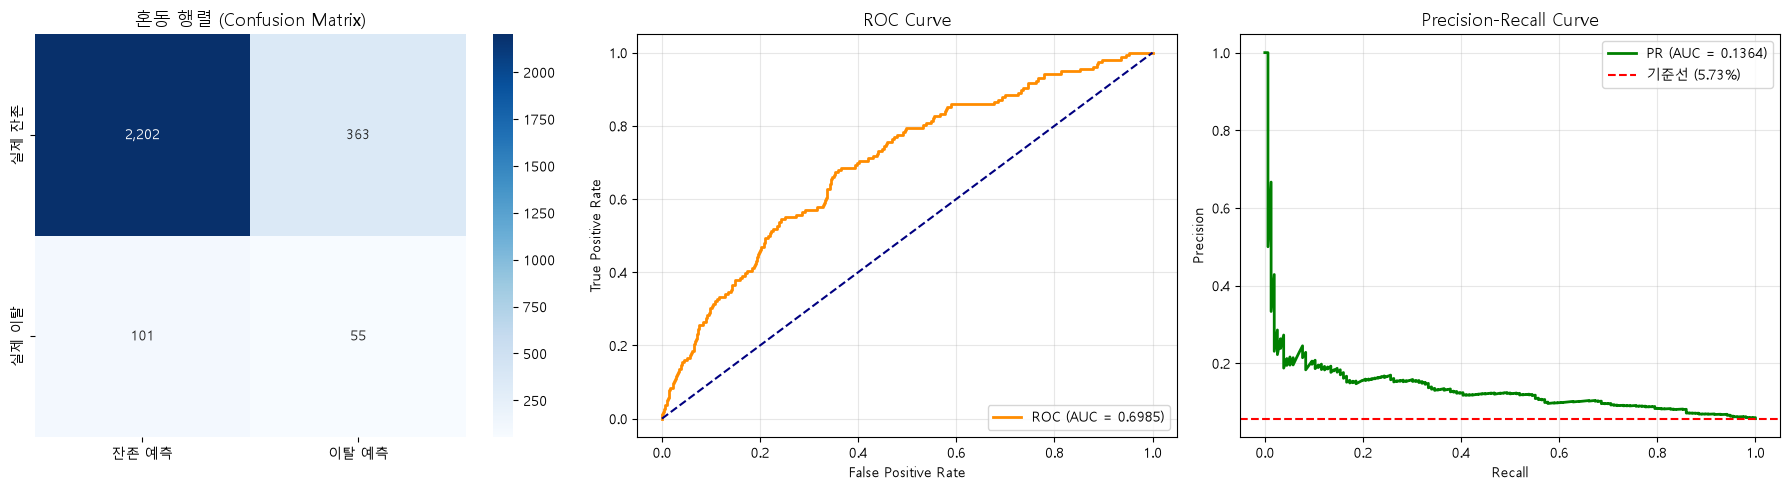

In [30]:
# 검증 세트 예측 확률 및 라벨
y_val_prob = rf_balanced.predict_proba(X_valid)[:, 1]
y_val_pred = (y_val_prob >= 0.5).astype(int)

print("\n=== Valid 분류 보고서 (기본 0.5 임계값) ===")
print(classification_report(y_valid, y_val_pred, digits=4, target_names=["잔존(0)", "이탈(1)"]))

roc_auc = roc_auc_score(y_valid, y_val_prob)
pr_auc = average_precision_score(y_valid, y_val_prob)
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC : {pr_auc:.4f}")

# 시각화
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (1) Confusion Matrix
cm = confusion_matrix(y_valid, y_val_pred)
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", ax=axes[0],
            xticklabels=["잔존 예측", "이탈 예측"], yticklabels=["실제 잔존", "실제 이탈"])
axes[0].set_title("혼동 행렬 (Confusion Matrix)", fontsize=13)

# (2) ROC 곡선
fpr, tpr, _ = roc_curve(y_valid, y_val_prob)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC (AUC = {roc_auc:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve", fontsize=13)
axes[1].legend(loc="lower right")
axes[1].grid(True, alpha=0.3)

# (3) Precision-Recall 곡선
precision_vals, recall_vals, _ = precision_recall_curve(y_valid, y_val_prob)
axes[2].plot(recall_vals, precision_vals, color="green", lw=2, label=f"PR (AUC = {pr_auc:.4f})")
axes[2].axhline(y=y_valid.mean(), color="red", linestyle="--", label=f"기준선 ({y_valid.mean()*100:.2f}%)")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].set_title("Precision-Recall Curve", fontsize=13)
axes[2].legend(loc="upper right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5. 최적 분류 임계값(Threshold) 튜닝

기본 임계값(0.5)은 불균형 데이터에서 항상 최적의 F1 점수를 보장하지 않습니다.  
0.1부터 0.9까지 임계값을 변경해가며 **F1-Score를 극대화하는 최적 임계값**을 탐색합니다.

최적 임계값: 0.530
최적 F1-Score: 0.2053 (Recall: 0.3205, Precision: 0.1511)


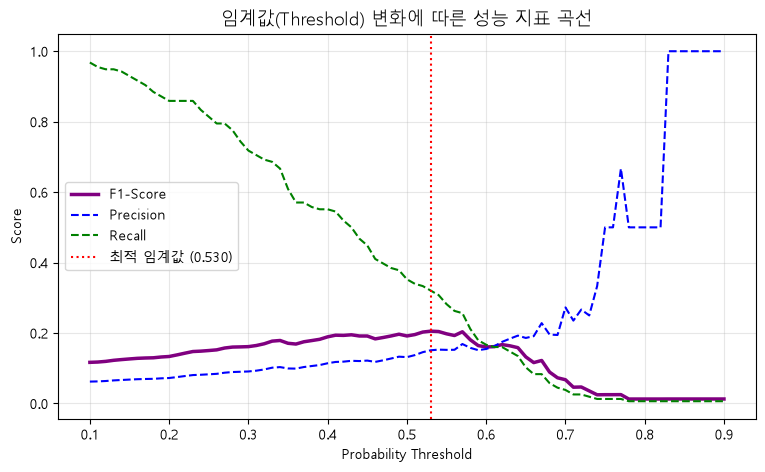

In [31]:
thresholds = np.linspace(0.1, 0.9, 81)
precisions, recalls, f1s = [], [], []

for th in thresholds:
    pred_th = (y_val_prob >= th).astype(int)
    precisions.append(precision_score(y_valid, pred_th, zero_division=0))
    recalls.append(recall_score(y_valid, pred_th, zero_division=0))
    f1s.append(f1_score(y_valid, pred_th, zero_division=0))

best_idx = np.argmax(f1s)
best_threshold = thresholds[best_idx]
best_f1 = f1s[best_idx]

print(f"최적 임계값: {best_threshold:.3f}")
print(f"최적 F1-Score: {best_f1:.4f} (Recall: {recalls[best_idx]:.4f}, Precision: {precisions[best_idx]:.4f})")

plt.figure(figsize=(9, 5))
plt.plot(thresholds, f1s, label="F1-Score", color="purple", lw=2.5)
plt.plot(thresholds, precisions, label="Precision", color="blue", linestyle="--")
plt.plot(thresholds, recalls, label="Recall", color="green", linestyle="--")
plt.axvline(best_threshold, color="red", linestyle=":", label=f"최적 임계값 ({best_threshold:.3f})")
plt.title("임계값(Threshold) 변화에 따른 성능 지표 곡선", fontsize=13)
plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 6. 피처 중요도(Feature Importance) 분석

랜덤 포레스트 모델이 어떤 고객 행동 변수를 바탕으로 이탈 여부를 판단했는지 Feature Importance를 추출합니다.

C:\Users\playdata2\AppData\Local\Temp\ipykernel_14224\2785049531.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importances, x="importance", y="feature", palette="viridis")


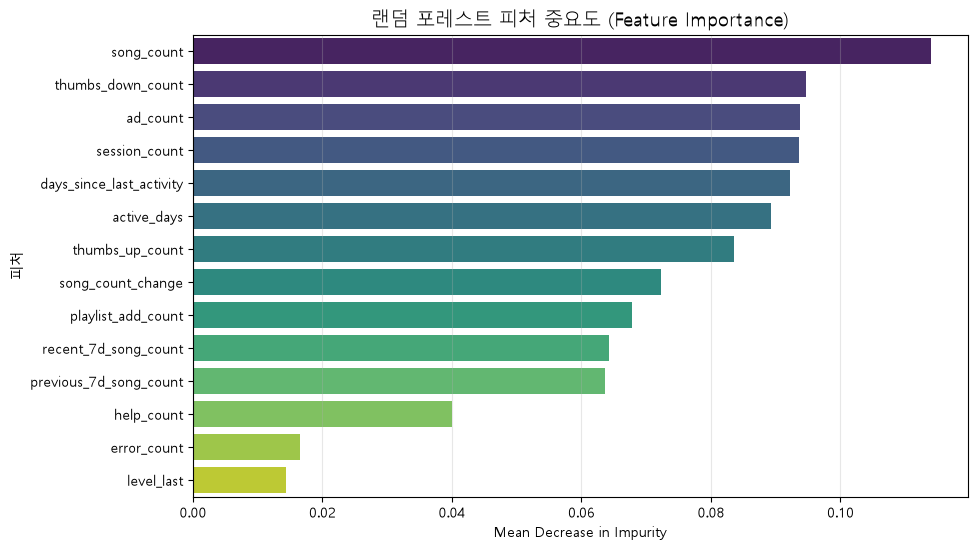

=== 피처 중요도 상위 5개 ===
                 feature  importance
              song_count    0.113977
       thumbs_down_count    0.094605
                ad_count    0.093779
           session_count    0.093543
days_since_last_activity    0.092203


In [32]:
feature_importances = pd.DataFrame({
    "feature": FEATURE_COLS,
    "importance": rf_balanced.feature_importances_
}).sort_values(by="importance", ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importances, x="importance", y="feature", palette="viridis")
plt.title("랜덤 포레스트 피처 중요도 (Feature Importance)", fontsize=14)
plt.xlabel("Mean Decrease in Impurity")
plt.ylabel("피처")
plt.grid(True, axis="x", alpha=0.3)
plt.show()

print("=== 피처 중요도 상위 5개 ===")
print(feature_importances.head(5).to_string(index=False))

## 7. 최종 테스트 세트(Test Set) 성능 검증 및 모델 저장

검증 세트로 튜닝한 최적 임계값(`best_threshold`)을 **최종 테스트 세트(`test_df`)**에 적용하여 과적합 없는 일반화 성능을 확인합니다.

In [42]:
# Test 세트 예측
y_test_prob = rf_balanced.predict_proba(X_test)[:, 1]
y_test_pred_default = (y_test_prob >= 0.5).astype(int)
y_test_pred_best = (y_test_prob >= best_threshold).astype(int)

test_acc = accuracy_score(y_test, y_test_pred_default)
test_pre = precision_score(y_test, y_test_pred_default)
test_re = recall_score(y_test, y_test_pred_default)
test_f1 = f1_score(y_test, y_test_pred_default)
test_roc = roc_auc_score(y_test, y_test_prob)
test_pr = average_precision_score(y_test, y_test_prob)

print("=" * 50)
print("랜덤포레스트 최종 테스트 세트 (Test Set) 평가 결과")
print("=" * 50)
print(f"Accyracy: {test_acc:.4f}")
print(f"Precision: {test_pre:.4f}")
print(f"Recall: {test_re:.4f}")
print(f"F1-Score: {test_f1:.4f}")
print(f"ROC-AUC: {test_roc:.4f}")
print(f"PR-AUC : {test_pr:.4f}")

print(f"\n[Report]")
print(classification_report(y_test, y_test_pred_default, digits=4, target_names=["잔존(0)", "이탈(1)"]))

# print(f"\n[최적 임계값 {best_threshold:.3f} 적용 시]")
# print(classification_report(y_test, y_test_pred_best, digits=4, target_names=["잔존(0)", "이탈(1)"]))

# 모델 및 메타데이터 저장
model_artifact = {
    "model": rf_balanced,
    "feature_cols": FEATURE_COLS,
    "best_threshold": best_threshold,
    "level_mapping": {"free": 0, "paid": 1},
    "test_roc_auc": test_roc,
    "test_pr_auc": test_pr
}

save_path = MODELS_DIR / "random_forest_v1.pkl"
joblib.dump(model_artifact, save_path)
print(f"\n모델 및 설정 저장 완료: {save_path}")

랜덤포레스트 최종 테스트 세트 (Test Set) 평가 결과
Accyracy: 0.8405
Precision: 0.1504
Recall: 0.3871
F1-Score: 0.2166
ROC-AUC: 0.7079
PR-AUC : 0.1660

[Report]
              precision    recall  f1-score   support

       잔존(0)     0.9591    0.8679    0.9112      2566
       이탈(1)     0.1504    0.3871    0.2166       155

    accuracy                         0.8405      2721
   macro avg     0.5547    0.6275    0.5639      2721
weighted avg     0.9130    0.8405    0.8716      2721


모델 및 설정 저장 완료: C:\Users\playdata2\Workspace\Projects\music_churn_data_v1\models\random_forest_v1.pkl
